In [ ]:
!git clone https://github.com/kefth/fashion-mnist.git

Cloning into 'fashion-mnist'...
remote: Enumerating objects: 151, done.
remote: Counting objects: 100% (57/57), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 151 (delta 52), reused 49 (delta 49), pack-reused 94 (from 1)
Receiving objects: 100% (151/151), 25.51 KiB | 435.00 KiB/s, done.
Resolving deltas: 100% (87/87), done.


In [ ]:
%cd fashion-mnist

/content/fashion-mnist


In [ ]:
import torch
print("PyTorch version:", torch.__version__)
print("GPU available?:", torch.cuda.is_available())

PyTorch version: 2.14.1+cu130
GPU available?: True


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import pandas as pd

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [ ]:
#device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# aug + norm
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Fashion-MNIST dtset
train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=train_transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# ResNet-18
import model
net = model.resnet18()
#change first conv layer to accept 1 channel instead of 3 (bc we only have BW pics)
net.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
net = net.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=0.001)

# quick training
print("Training!!")
net.train()
for epoch in range(15):
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = net(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    print(f"Epoch {epoch+1}/5 - Loss: {running_loss/len(train_loader):.4f}")

#save weights
torch.save(net.state_dict(), "fashion_resnet18.pth")
print("Model trained and saved as 'fashion_resnet18.pth'!")

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 208kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.9MB/s]


Training!!
Epoch 1/5 - Loss: 0.6119
Epoch 2/5 - Loss: 0.4232
Epoch 3/5 - Loss: 0.3676
Epoch 4/5 - Loss: 0.3425
Epoch 5/5 - Loss: 0.3211
Epoch 6/5 - Loss: 0.3036
Epoch 7/5 - Loss: 0.2892
Epoch 8/5 - Loss: 0.2787
Epoch 9/5 - Loss: 0.2647
Epoch 10/5 - Loss: 0.2565
Epoch 11/5 - Loss: 0.2491
Epoch 12/5 - Loss: 0.2417
Epoch 13/5 - Loss: 0.2333
Epoch 14/5 - Loss: 0.2264
Epoch 15/5 - Loss: 0.2226
Model trained and saved as 'fashion_resnet18.pth'!


^ aprox 4-5 min on GPU

In [ ]:
# test set eval and collect predix
net.eval()

all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = net(images)

        #logits to probs
        probs = torch.softmax(outputs, dim=1)

        #get predicted class
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

#for Fashion-MNIST
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

#results df
df_results = pd.DataFrame({
    'image_idx': range(len(all_labels)),
    'true_label': [class_names[i] for i in all_labels],
    'pred_label': [class_names[i] for i in all_preds],
    'is_correct': [l == p for l, p in zip(all_labels, all_preds)],
    'max_confidence': [max(p) for p in all_probs]
})

#CSV
df_results.to_csv("phase1_model_predictions.csv", index=False)

#summary
accuracy = df_results['is_correct'].mean() * 100
print(f"Overall Test Accuracy: {accuracy:.2f}%\n")
print("First 5 predictions:")
print(df_results.head())

Overall Test Accuracy: 92.10%

First 5 predictions:
   image_idx  true_label  pred_label  is_correct  max_confidence
0          0  Ankle boot  Ankle boot        True        0.999924
1          1    Pullover    Pullover        True        0.999836
2          2     Trouser     Trouser        True        0.999946
3          3     Trouser     Trouser        True        0.999987
4          4       Shirt       Shirt        True        0.858259


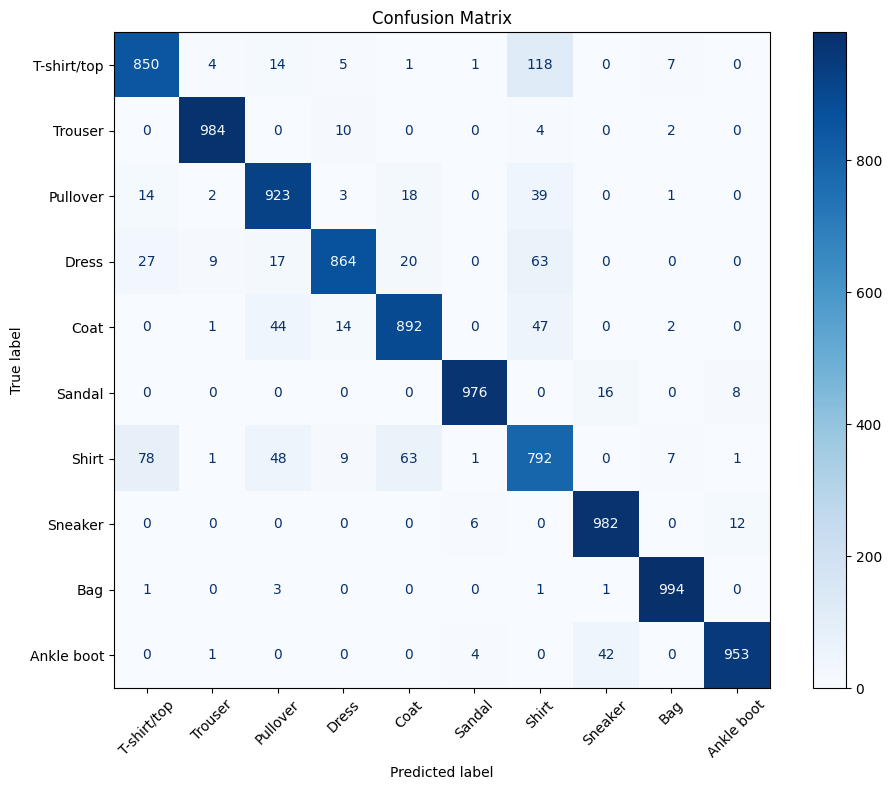

In [ ]:
cm = confusion_matrix(df_results['true_label'], df_results['pred_label'], labels=class_names)

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues', xticks_rotation=45, ax=ax)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

In [ ]:
# extract features (needed for PCA and tsne) (see if u can reuse it for other things too)
features = []

def hook_fn(module, input, output):
    features.append(output.squeeze().cpu().numpy())

handle = net.avgpool.register_forward_hook(hook_fn)

net.eval()
with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)
        _ = net(images)

handle.remove()
all_features = np.concatenate(features, axis=0)

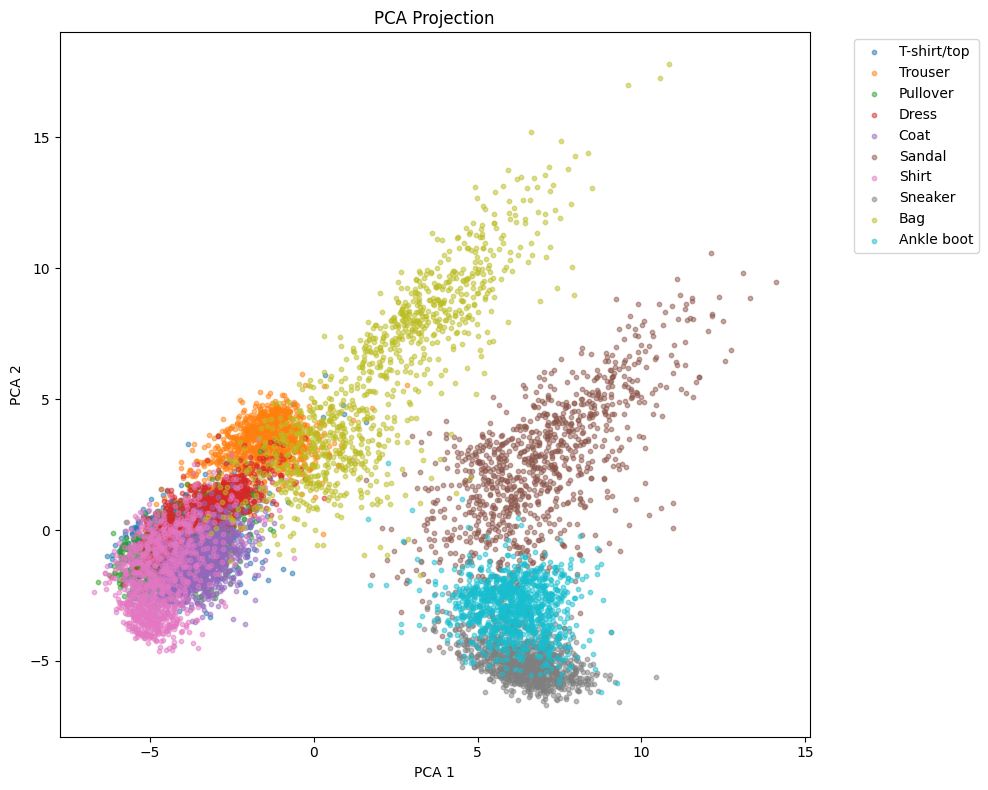

In [ ]:
# PCA

pca = PCA(n_components=2, random_state=42)
pca_results = pca.fit_transform(all_features)

plt.figure(figsize=(10, 8))
for i, name in enumerate(class_names):
    idx = (df_results['true_label'] == name)
    plt.scatter(pca_results[idx, 0], pca_results[idx, 1], label=name, alpha=0.5, s=10)

plt.title(f"PCA Projection")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig("pca_projection.png", dpi=300)
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


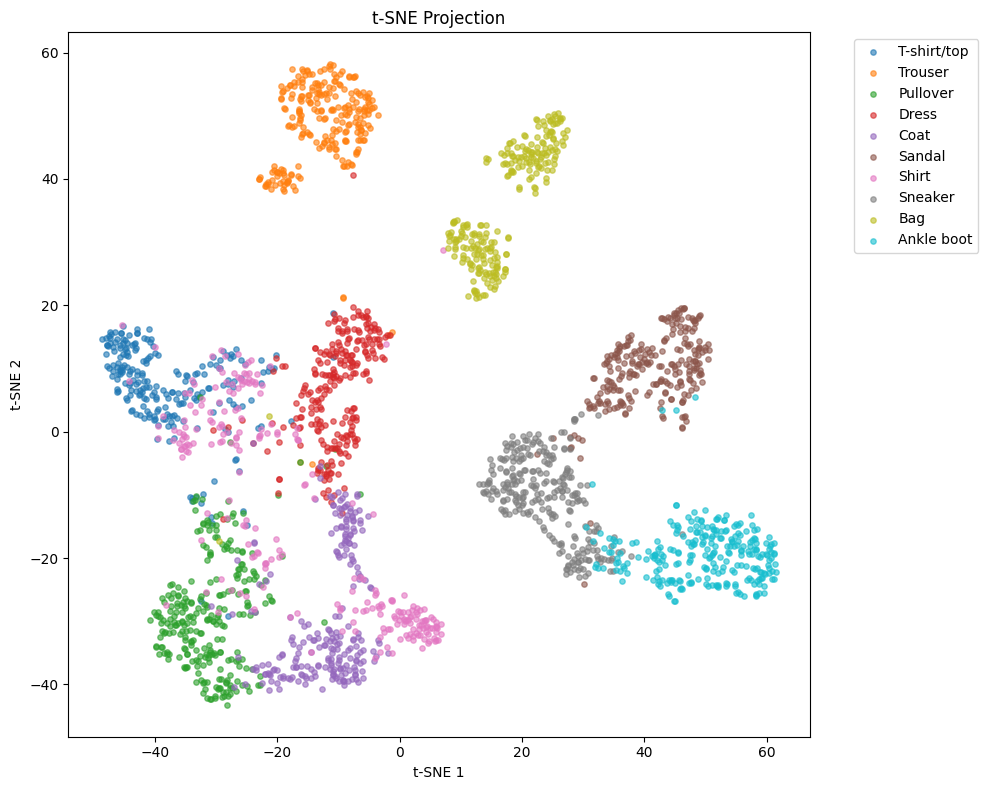

In [ ]:
#tsne

#subsample 2.5k points for better clusters

np.random.seed(42)
subsample_indices = np.random.choice(len(all_features), size=2500, replace=False)

tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_iter=1000)
tsne_results = tsne.fit_transform(all_features[subsample_indices])

sub_df = df_results.iloc[subsample_indices]

plt.figure(figsize=(10, 8))
for name in class_names:
    idx = (sub_df['true_label'] == name).values
    plt.scatter(tsne_results[idx, 0], tsne_results[idx, 1], label=name, alpha=0.6, s=15)

plt.title("t-SNE Projection")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig("tsne_projection.png", dpi=300)
plt.show()


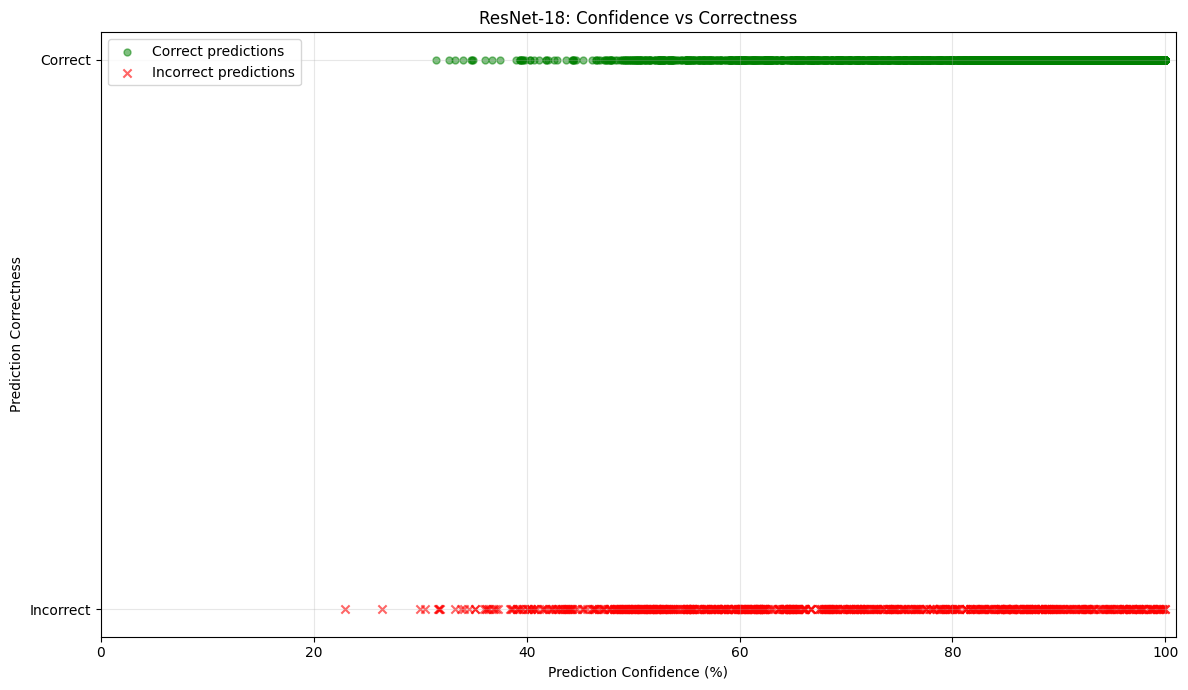

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

# Correct predictions
correct = df_results[df_results['is_correct'] == True]

# Incorrect predictions
incorrect = df_results[df_results['is_correct'] == False]

plt.scatter(
    correct['max_confidence'] * 100,
    [1] * len(correct),
    color='green',
    alpha=0.5,
    label='Correct predictions',
    s=25
)

plt.scatter(
    incorrect['max_confidence'] * 100,
    [0] * len(incorrect),
    color='red',
    alpha=0.6,
    label='Incorrect predictions',
    marker='x',
    s=35
)

plt.yticks([0, 1], ['Incorrect', 'Correct'])
plt.xlabel('Prediction Confidence (%)')
plt.ylabel('Prediction Correctness')
plt.title('ResNet-18: Confidence vs Correctness')

plt.xlim(0, 101)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

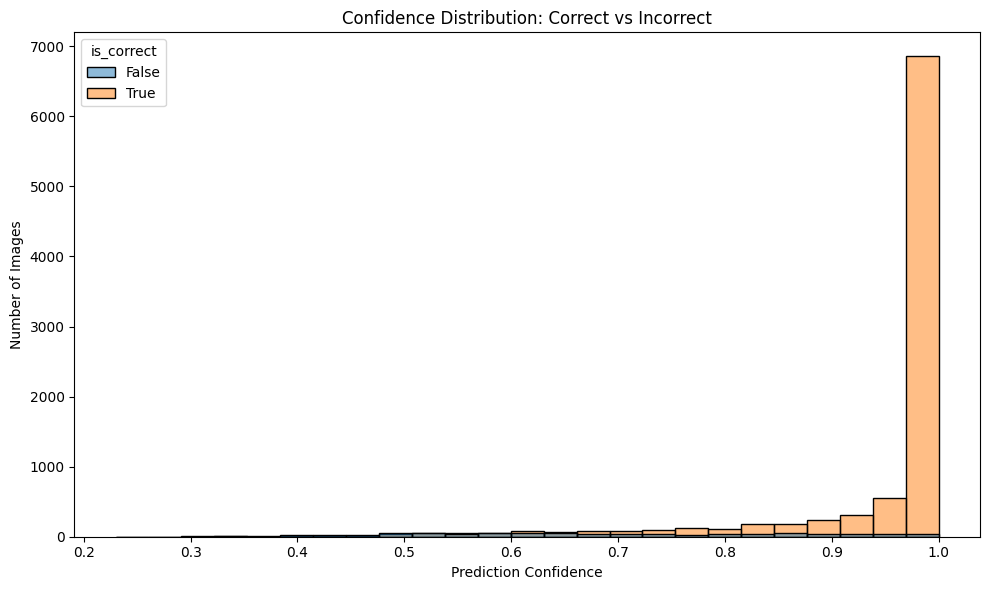

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_results,
    x='max_confidence',
    hue='is_correct',
    bins=25,
    stat='count',
    common_norm=False,
    alpha=0.5
)

plt.xlabel('Prediction Confidence')
plt.ylabel('Number of Images')
plt.title('Confidence Distribution: Correct vs Incorrect')
plt.tight_layout()
plt.show()

In [ ]:
high_conf_wrong = df_results[
    (df_results['is_correct'] == False) &
    (df_results['max_confidence'] >= 0.90)
]

print("High-confidence incorrect predictions:",
      len(high_conf_wrong))

print(high_conf_wrong.head(20))

High-confidence incorrect predictions: 113
      image_idx   true_label   pred_label  is_correct  max_confidence
23           23   Ankle boot       Sandal       False        0.961362
32           32        Dress      Trouser       False        0.961180
68           68   Ankle boot      Sneaker       False        0.963104
147         147        Shirt        Dress       False        0.921034
244         244        Shirt     Pullover       False        0.994323
316         316   Ankle boot      Sneaker       False        0.957217
441         441   Ankle boot      Sneaker       False        0.947676
454         454  T-shirt/top        Shirt       False        0.975347
476         476         Coat          Bag       False        0.932920
661         661        Dress  T-shirt/top       False        0.923402
732         732     Pullover  T-shirt/top       False        0.941753
787         787      Trouser        Dress       False        0.989360
979         979        Dress  T-shirt/top      

In [ ]:
print(
    high_conf_wrong.groupby(
        ['true_label', 'pred_label']
    ).size().sort_values(ascending=False)
)

true_label   pred_label 
Ankle boot   Sneaker        13
Shirt        Coat           13
             Pullover       11
Coat         Pullover       11
Shirt        T-shirt/top    10
Sandal       Sneaker         7
T-shirt/top  Shirt           7
             Pullover        4
             Dress           3
Shirt        Bag             3
Dress        Trouser         3
T-shirt/top  Bag             3
Ankle boot   Sandal          2
Trouser      Dress           2
Pullover     T-shirt/top     2
             Shirt           2
Coat         Shirt           2
Dress        Pullover        2
             T-shirt/top     2
Pullover     Coat            2
Sneaker      Ankle boot      2
Dress        Coat            1
Coat         Bag             1
             Dress           1
Shirt        Dress           1
Sandal       Ankle boot      1
Sneaker      Sandal          1
T-shirt/top  Sandal          1
dtype: int64


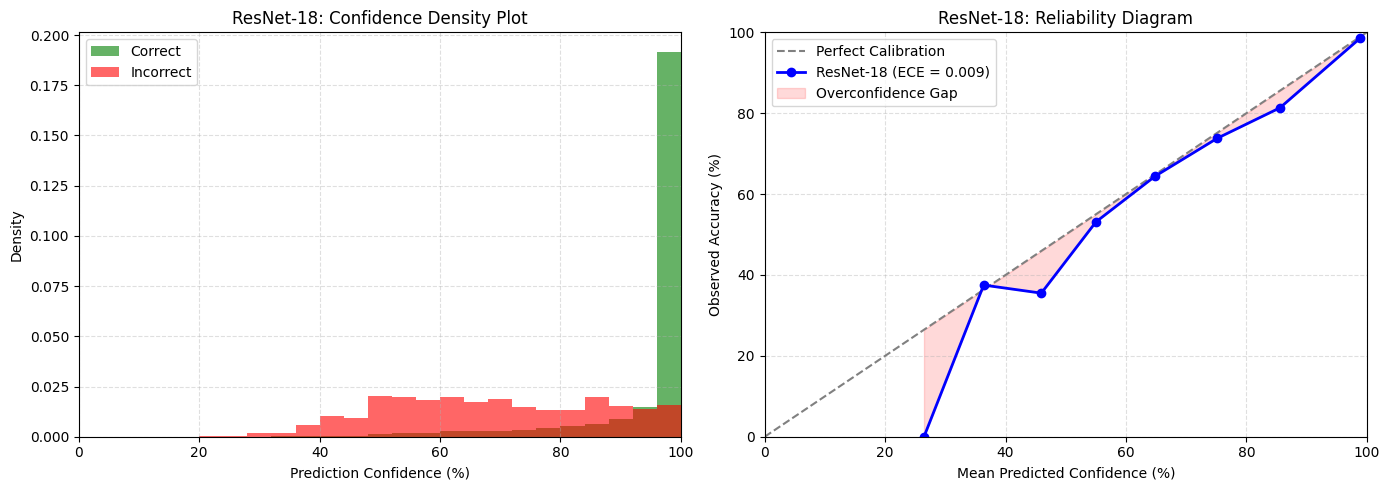

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Confidence Density Plot
bins = np.linspace(0, 100, 26)
ax1.hist(df_results.loc[df_results['is_correct'], 'max_confidence'] * 100, bins=bins, density=True, alpha=0.6, color='green', label='Correct')
ax1.hist(df_results.loc[~df_results['is_correct'], 'max_confidence'] * 100, bins=bins, density=True, alpha=0.6, color='red', label='Incorrect')

ax1.set_title('ResNet-18: Confidence Density Plot')
ax1.set_xlabel('Prediction Confidence (%)')
ax1.set_ylabel('Density')
ax1.set_xlim(0, 100)
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.4)

# Reliability Diagram
n_bins = 10
bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
bin_acc = []
bin_conf = []
ece = 0.0

conf_vals = df_results['max_confidence'].values
corr_vals = df_results['is_correct'].values

for i in range(n_bins):
    in_bin = (conf_vals > bin_edges[i]) & (conf_vals <= bin_edges[i + 1])
    if np.sum(in_bin) > 0:
        acc = np.mean(corr_vals[in_bin])
        conf = np.mean(conf_vals[in_bin])
        bin_acc.append(acc * 100)
        bin_conf.append(conf * 100)
        ece += (np.sum(in_bin) / len(conf_vals)) * np.abs(acc - conf)
    else:
        bin_acc.append(np.nan)
        bin_conf.append(((bin_edges[i] + bin_edges[i + 1]) / 2) * 100)

ideal = np.linspace(0, 100, 100)
ax2.plot(ideal, ideal, linestyle='--', color='gray', label='Perfect Calibration')
ax2.plot(bin_conf, bin_acc, marker='o', linewidth=2, color='blue', label=f'ResNet-18 (ECE = {ece:.3f})')
ax2.fill_between(bin_conf, bin_acc, bin_conf, color='red', alpha=0.15, label='Overconfidence Gap')

ax2.set_title('ResNet-18: Reliability Diagram')
ax2.set_xlabel('Mean Predicted Confidence (%)')
ax2.set_ylabel('Observed Accuracy (%)')
ax2.set_xlim(0, 100)
ax2.set_ylim(0, 100)
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

